# 03 - Cepstral / feature-space exploratory data analysis (EDA), Stage 2

**Question this notebook answers:** of the controlled representation choices in the Stage 2
`feat_a`-`feat_f` grid (linear vs. mel frequency warping, discrete cosine transform (DCT)
decorrelation on or off, coefficient truncation, static plus delta and delta-delta), which
ones visibly change class separability *in feature space*, and is any separating direction
consistent across attack (generator) systems?

**Mode:** the notebook looks for the ASVspoof 2019 logical access (LA) download at
`configs/data.yaml: dataset.root`; the stored run prints `MODE: REAL DATA`. If the download is
absent, it falls back to a small **synthetic mini-manifest** so the cells still execute;
results in that mode are pipeline checks only.

All six variants (`configs/features.yaml`) are produced by `audio_df.features.cepstral.extract`; this
notebook defines no short-time Fourier transform (STFT), filterbank or DCT logic of its own,
only calls into `features.py`, `stats.py` and `visualization.py`, plus
`sklearn.decomposition.PCA` for an exploratory principal component analysis (PCA) projection
(explicitly *not* evidence of separability). Fitting **the same backend** to each
representation is a separate measurement (the A1 linear-frequency vs. mel-frequency cepstral
coefficient (LFCC vs. MFCC) runs logged in `runs/REGISTRY.md`); this notebook only
characterises each representation descriptively, on a 90-clip stratified sample (15 clips per
split-by-label cell).

In [1]:
from __future__ import annotations

import tempfile
from pathlib import Path


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from sklearn.decomposition import PCA

from audio_df.features import audio
from audio_df.data import manifests as data
from audio_df.features import cepstral as features
from audio_df.evaluation import stats
from audio_df.evaluation import visualization as viz
from audio_df.data.synthetic import build_synthetic_asvspoof_tree


def _find_repo_root(start: Path) -> Path:
    cur = start.resolve()
    for _ in range(6):
        if (cur / "pyproject.toml").exists():
            return cur
        cur = cur.parent
    raise RuntimeError(f"could not find repo root (pyproject.toml) from {start}")


REPO_ROOT = _find_repo_root(Path.cwd())
pd.set_option("display.width", 120)

/Users/zuttome/LocalDocs/Learning/College/NUS/MTech-AIS/PS/GC2/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
_data_cfg_path = REPO_ROOT / "configs" / "data.yaml"
_real_cfg = yaml.safe_load(_data_cfg_path.read_text())
_real_root = Path(_real_cfg["dataset"]["root"])
if not _real_root.is_absolute():
    _real_root = REPO_ROOT / _real_root

USE_REAL_DATA = _real_root.exists() and any(_real_root.rglob("*.flac"))

if USE_REAL_DATA:
    MODE = "REAL DATA"
    cfg = _real_cfg
    cfg["dataset"]["root"] = str(_real_root)
    cfg["dataset"]["protocol_dir"] = str(REPO_ROOT / cfg["dataset"]["protocol_dir"])
    _tmpdir_handle = None
else:
    MODE = "SYNTHETIC MINI-MANIFEST (no ASVspoof download found)"
    _tmpdir_handle = tempfile.TemporaryDirectory(prefix="asvspoof_synth_")
    cfg = build_synthetic_asvspoof_tree(Path(_tmpdir_handle.name), seed=777)

print(f"MODE: {MODE}")

manifest = data.build_manifest(cfg)
print(f"manifest: {len(manifest)} rows")

FEAT_CFG = yaml.safe_load((REPO_ROOT / "configs" / "features.yaml").read_text())
FEAT_CFG.setdefault("sr", 16000)
VARIANTS = list(FEAT_CFG["variants"].keys())
print(f"variants: {VARIANTS}")

MODE: REAL DATA
manifest: 121461 rows
variants: ['feat_a_linear_logfb', 'feat_b_lfcc_full', 'feat_c_lfcc_trunc', 'feat_d_mel_logfb', 'feat_e_mfcc', 'feat_f_lfcc_deltas']


In [3]:
# Keep this fast in both modes: a small stratified sample, six variants extracted per
# utterance (mean-pooled over frames into one vector per utterance -- the same aggregation
# convention notebook 02 uses for spectra, so per-utterance rows can feed distributions,
# effect sizes, correlation and PCA without a variable-length-sequence complication).
N_PER_CELL = 15
rng = np.random.default_rng(1)


def _stratified_sample(df: pd.DataFrame, n_per_cell: int) -> pd.DataFrame:
    parts = []
    for _, group in df.groupby(["split", "label"], dropna=False):
        take = min(n_per_cell, len(group))
        idx = rng.choice(group.index.to_numpy(), size=take, replace=False)
        parts.append(df.loc[idx])
    return pd.concat(parts).reset_index(drop=True)


eda_df = _stratified_sample(manifest, N_PER_CELL)
print(f"EDA sample: {len(eda_df)} of {len(manifest)} manifest rows")

variant_vecs: dict[str, np.ndarray] = {}
meta_rows = []
for variant in VARIANTS:
    vecs = []
    for row in eda_df.itertuples(index=False):
        x, sr = audio.load_audio(row.path, target_sr=FEAT_CFG["sr"])
        feat = features.extract(x, variant, FEAT_CFG)  # [T, D]
        vecs.append(feat.mean(axis=0))
    variant_vecs[variant] = np.stack(vecs)
    if not meta_rows:
        meta_rows = list(eda_df[["utt_id", "label", "attack_id", "split"]].itertuples(index=False))

meta_df = pd.DataFrame(meta_rows, columns=["utt_id", "label", "attack_id", "split"])
for v, mat in variant_vecs.items():
    print(f"{v}: D={mat.shape[1]}")

EDA sample: 90 of 121461 manifest rows
feat_a_linear_logfb: D=20
feat_b_lfcc_full: D=20
feat_c_lfcc_trunc: D=13
feat_d_mel_logfb: D=20
feat_e_mfcc: D=13
feat_f_lfcc_deltas: D=60


## Per-dimension distributions (one variant)

`feat_b_lfcc_full` (linear filterbank, full DCT) -- the first four coefficients, pooled by class.

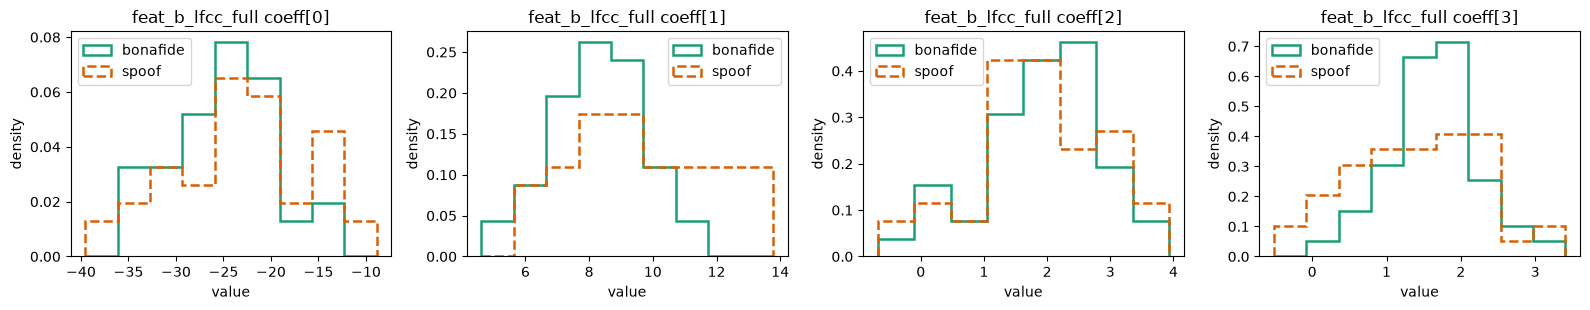

In [4]:
demo_variant = "feat_b_lfcc_full"
demo_mat = variant_vecs[demo_variant]
labels = meta_df["label"].to_numpy()

fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for dim, ax in enumerate(axes):
    values_by_class = {lab: demo_mat[labels == lab, dim] for lab in np.unique(labels)}
    viz.plot_class_distributions(values_by_class, ax=ax)
    ax.set_title(f"{demo_variant} coeff[{dim}]")
fig.tight_layout()
plt.show()

### What this shows

Each panel is one LFCC coefficient, averaged over the frames of each clip, for 45 real (green)
and 45 fake (orange) clips. The two curves **overlap heavily**: c1 and c3 show small shifts
(the fake distributions are wider), but no single coefficient separates real from fake.

### What it means

This is expected, and it is the reason a model is needed at all. A detector does not look at
one coefficient at a time. A1's Gaussian mixture model (GMM) scores all 60 numbers of every
frame together (20 coefficients plus their first and second differences over time), and
reaches a measured 9.56 % equal error rate (EER) on the unseen-attack eval split
(`runs/REGISTRY.md`, run `E-20261001-e1-a1-raw`) even though no single coefficient
separates the classes. Features that each overlap can still separate the classes in
combination. The next plots ask a narrower question: *which* coefficients differ at all.

## Effect size per dimension, across all six variants

The same `stats.per_bin_effect_size` used in notebook 02, here applied along the coefficient
axis instead of the frequency-bin axis; it is a standardised-mean-difference computation and
is agnostic to what the columns represent.

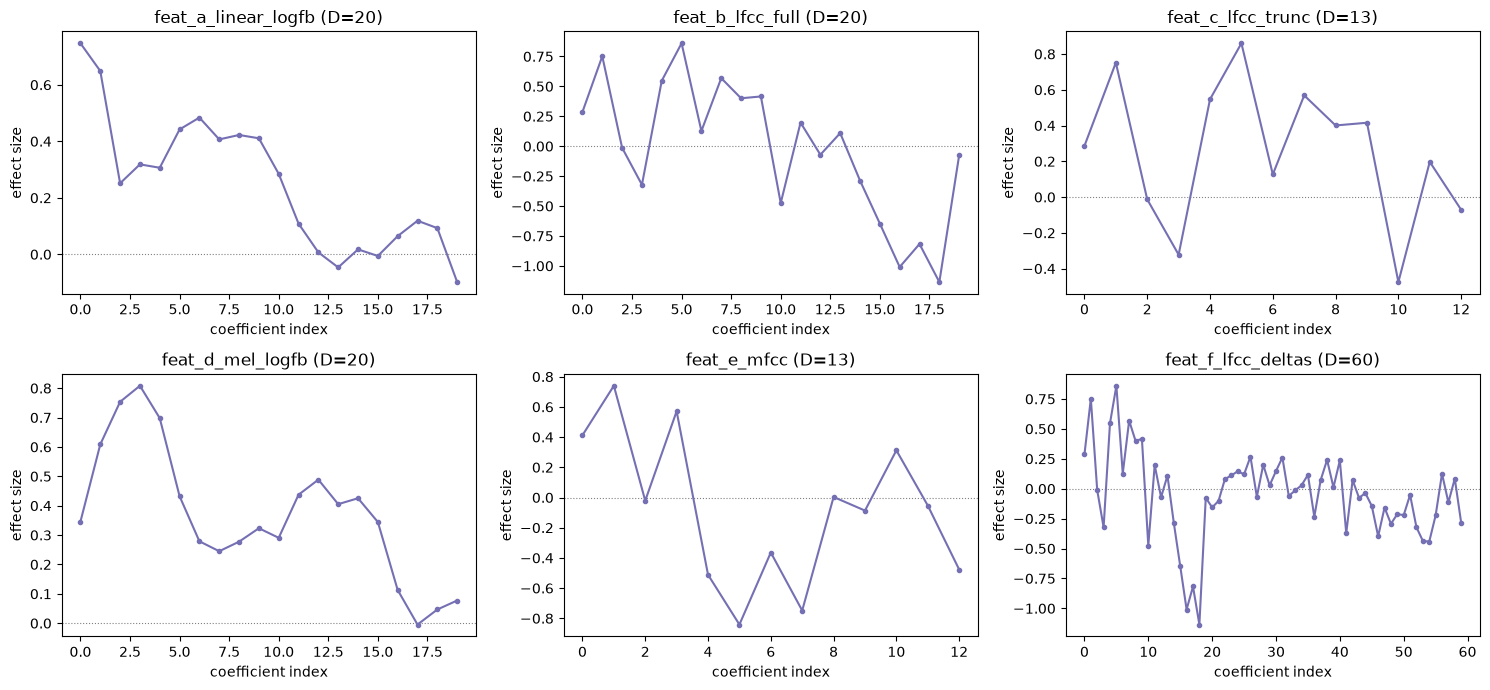

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, variant in zip(axes.ravel(), VARIANTS, strict=False):
    mat = variant_vecs[variant]
    eff = stats.per_bin_effect_size(mat[labels == "spoof"], mat[labels == "bonafide"])
    viz.plot_effect_size_per_bin(eff, np.arange(len(eff)), ax=ax)
    ax.set_xlabel("coefficient index")
    ax.set_title(f"{variant} (D={mat.shape[1]})")
fig.tight_layout()
plt.show()

### What this shows

Each dot is Cohen's *d* (fake minus real) for one dimension of one representation. Six panels,
six ways of building the features:

| panel | what it is |
|---|---|
| a | linear log filterbank, no DCT |
| b | linear-frequency cepstral coefficients (LFCC), all 20 |
| c | LFCC cut to 13 |
| d | mel log filterbank |
| e | mel-frequency cepstral coefficients (MFCC), 13 |
| f | LFCC plus first and second differences over time (Δ and ΔΔ) |

### What it means

**Coefficient numbers mean different things in different panels.** For a filterbank (a, d) the
index is a frequency channel, low to high. For a cepstrum (b, c, e, f) it is a "shape"
component after the DCT. On a mel axis the channels sit at different frequencies than on a
linear axis. So compare *patterns within* a panel, not index 5 across panels.

- **a (linear filterbank).** The effect is positive in the lower channels, largest at the
  lowest (about +0.75), and fades to about 0 from channel 12 upward (above roughly 4 kHz). A
  difference that has the same sign across the band and is biggest at the bottom is what a
  **level and silence** difference looks like, not a high-frequency artefact. One consistent
  reading (a hypothesis, not tested here) is that fakes carry less silence (notebooks 01 and
  02), so their frame-averaged log energy is higher.
- **b and c (LFCC, 20 against 13).** Panel b is read in the next section. Panel c is the same
  curve, cut off at c12. **Cutting to 13 discards c13-c19, where the strongest negative
  differences are** (c15-c18), which argues for keeping all 20, as the official B02 baseline
  does.
- **d and e (mel).** Effects are spread over different indices. The mel scale places 15 of its
  20 filter centres below 4 kHz (7 below 1 kHz, against 2 for the linear bank; see
  `Miscellaneous/research/knowledge/methods/lfcc-vs-mfcc-explained.md` §2), so its channels and coefficients
  describe the low band in more detail and the high band less.
- **f (with Δ and ΔΔ).** The first 20 dots are panel b. The Δ/ΔΔ dimensions are mostly small
  (within about ±0.45). That does *not* make them useless to A1: dynamics matter for detection
  in the literature (Sahidullah et al. 2015, Table 3), but a clip-level average of "how fast
  things change" hides most of that, so this plot cannot judge them.

**Sample size:** with 45 clips per class, |d| below about 0.4 is noise (the next section draws
the band). This plot is a map of where to look, not proof.

### Reading the LFCC panel: which coefficients differ, and is it more than noise?

The same effect sizes for `feat_b_lfcc_full` only, drawn with two aids:

- **A grey band of ±2 standard errors.** With 45 real and 45 fake clips, a Cohen's *d* inside
  the band is indistinguishable from zero. Only dots outside it are worth reading.
- **Shaded regions naming what each group of coefficients describes.** The DCT turns the 20 log
  band energies into coefficients with a fixed meaning (see
  `Miscellaneous/research/knowledge/methods/lfcc-vs-mfcc-explained.md` §1):
  - **c0** is overall level (loudness, and silence);
  - **c1** is spectral tilt (low band against high band);
  - **c2-c6** are the broad envelope, the formant-scale shape;
  - **c7 upward** is finer and finer ripple across the spectrum.

**Note on stored output:** the next cell has no saved output in this notebook. Its *d* values
are the same as panel b of the figure above (same sample and computation); re-run the cell to
draw the noise band and print which coefficients fall outside it. In panel b the largest
positive effects are at c1 and c5 (about +0.75 and +0.86) and the largest negative effects at
c16 and c18 (about -1.0 and -1.1).

In [ ]:
lfcc = variant_vecs["feat_b_lfcc_full"]
a_s, a_b = lfcc[labels == "spoof"], lfcc[labels == "bonafide"]
n_s, n_b = len(a_s), len(a_b)
d_lfcc = stats.per_bin_effect_size(a_s, a_b)
se = np.sqrt((n_s + n_b) / (n_s * n_b) + d_lfcc**2 / (2 * (n_s + n_b)))   # standard error of d

fig, ax = plt.subplots(figsize=(11, 4))
k = np.arange(len(d_lfcc))
for lo, hi, name, shade in [(-0.5, 0.5, "c0\nlevel", "#f2f2f2"), (0.5, 1.5, "c1\ntilt", "#e6e6e6"),
                            (1.5, 6.5, "c2-c6\nenvelope", "#f2f2f2"), (6.5, 19.5, "c7-c19\nfiner and finer detail", "#e6e6e6")]:
    ax.axvspan(lo, hi, color=shade, zorder=0)
    ax.text((lo + hi) / 2, 1.12, name, ha="center", va="bottom", fontsize=8, color="0.3")
ax.fill_between(k, -2 * se, 2 * se, color="0.75", alpha=0.6, label="±2 standard errors (noise level)")
ax.axhline(0, color="0.4", lw=0.8)
ax.plot(k, d_lfcc, "o-", color="0.15", label="Cohen's d, fake minus real")
ax.set_xticks(k)
ax.set_xlabel("LFCC coefficient")
ax.set_ylabel("Cohen's d (fake − real)")
ax.set_ylim(-1.6, 1.45)
ax.legend(loc="lower left", fontsize=8, frameon=False)
ax.set_title("feat_b_lfcc_full: per-coefficient difference between fake and real (90-clip sample)")
fig.tight_layout()
plt.show()

print("coef     d    outside ±2SE?")
for i, (dv, s) in enumerate(zip(d_lfcc, se, strict=True)):
    print(f"c{i:<3} {dv:+6.2f}   {'yes' if abs(dv) > 2 * s else ''}")

## Correlation matrices: does the DCT decorrelate, as claimed?

`feat_a_linear_logfb` (no DCT) vs. `feat_b_lfcc_full` (same filterbank, full orthonormal DCT) on
bonafide utterances only, so any difference in off-diagonal structure is attributable to the
DCT step alone, not a class or attack effect.

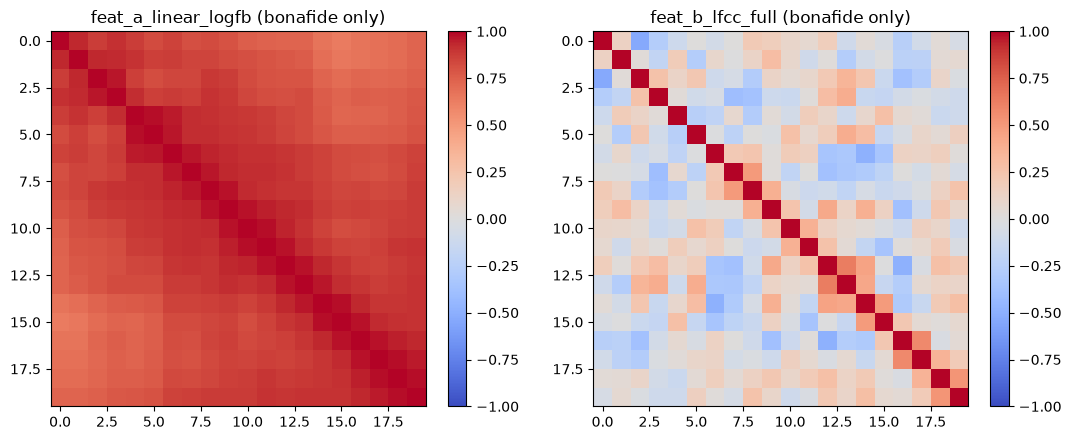

feat_a_linear_logfb: mean |off-diagonal correlation| = 0.851
feat_b_lfcc_full: mean |off-diagonal correlation| = 0.166


In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, variant in zip([ax1, ax2], ["feat_a_linear_logfb", "feat_b_lfcc_full"], strict=False):
    mat = variant_vecs[variant][labels == "bonafide"]
    corr = np.corrcoef(mat.T)
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_title(f"{variant} (bonafide only)")
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()

for variant in ["feat_a_linear_logfb", "feat_b_lfcc_full"]:
    mat = variant_vecs[variant][labels == "bonafide"]
    corr = np.corrcoef(mat.T)
    off_diag = corr[~np.eye(corr.shape[0], dtype=bool)]
    print(f"{variant}: mean |off-diagonal correlation| = {np.mean(np.abs(off_diag)):.3f}")

### What this shows

The correlation between every pair of dimensions, on real clips only. Left: the 20 log
filterbank channels (no DCT), with a measured mean |off-diagonal correlation| of **0.851**.
Right: the same channels after the DCT, **0.166**.

### What it means

- **High correlation without the DCT is normal, not special to voices.** Neighbouring frequency
  bands rise and fall together: a louder frame lifts *every* band. So the 20 raw channels carry
  much the same information many times over, mostly "how loud is this frame".
- **The DCT keeps all the information but re-expresses it** in 20 new directions that barely
  overlap. With all 20 coefficients kept it is fully reversible.
- **Why this matters for the model.** A1's GMM uses *diagonal* covariances: it assumes the
  dimensions are independent within each mixture component. On raw filterbanks that assumption
  is badly wrong; after the DCT it is roughly right, which is why classic GMM recipes put a DCT
  before the model.
- **Why this matters for understanding.** After the orthonormal DCT, a pure gain change moves
  only c0: the DCT of a constant vector is zero for every coefficient above c0, so a 10 dB drop
  shifts c0 by -4.47 and leaves c1 onwards unchanged (derivation in
  `Miscellaneous/research/knowledge/methods/lfcc-vs-mfcc-explained.md` §1). So "fakes differ in c0" points to
  a level or silence difference, a shortcut, while "fakes differ in c15-c18" points to a
  difference in fine spectral detail, a possible synthesis cue. On the tangled raw channels
  those two could not be told apart.

## PCA (exploratory visualization only, not evidence of separability)

PCA, t-distributed stochastic neighbour embedding (t-SNE) and uniform manifold approximation
and projection (UMAP) give exploratory pictures, never evidence of separability on their own.
PCA is shown here for all six variants to see whether an obvious 2D linear-projection gap
appears at all. Its *absence* is not evidence of inseparability either, since PCA is not
distance- or margin-optimal for classification.

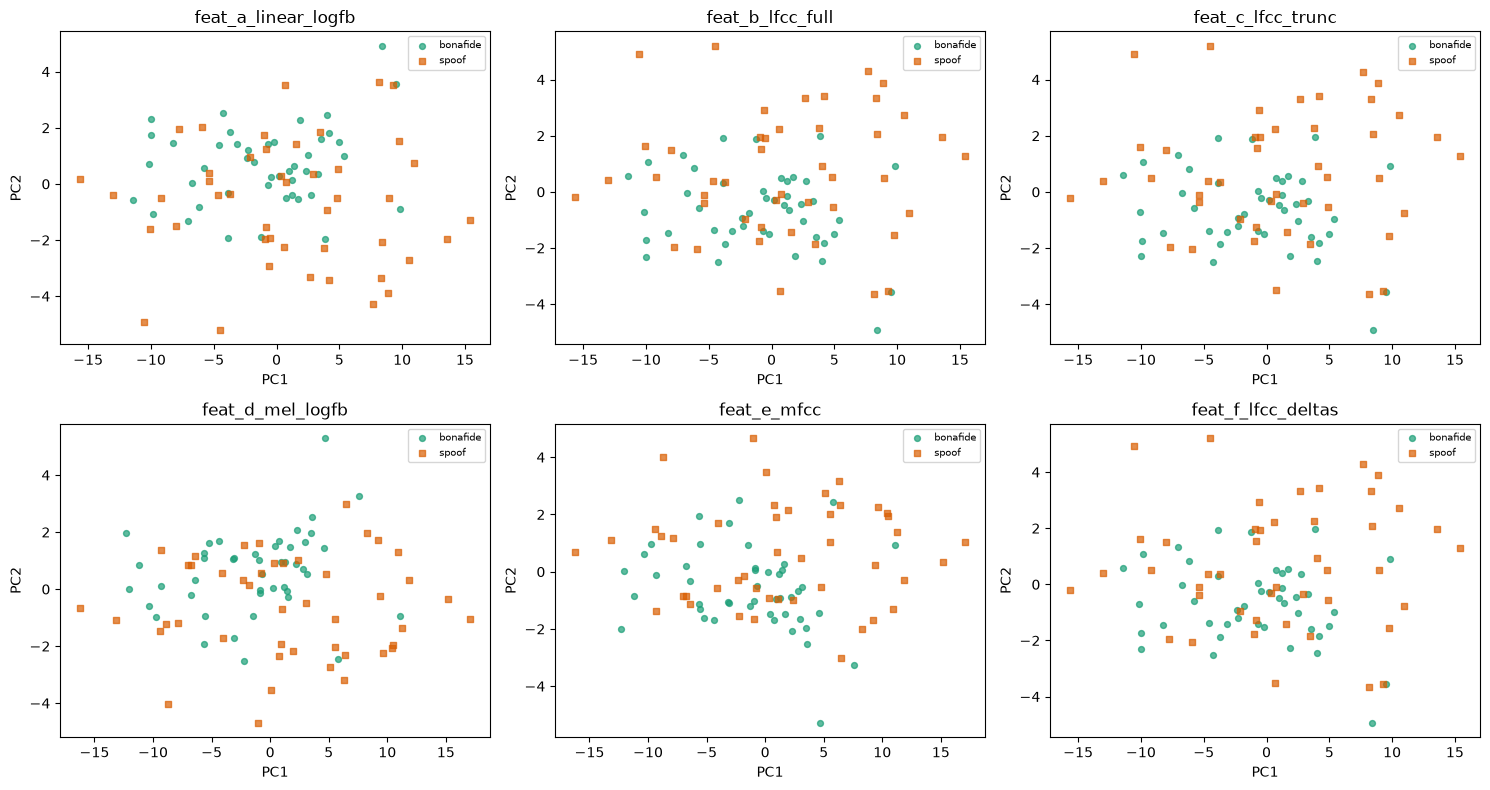

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, variant in zip(axes.ravel(), VARIANTS, strict=False):
    mat = variant_vecs[variant]
    proj = PCA(n_components=2, random_state=0).fit_transform(mat)
    marker_by_class = {"bonafide": "o", "spoof": "s"}
    for lab in np.unique(labels):
        mask = labels == lab
        color = viz.CLASS_COLORS.get(lab, "#333333")
        marker = marker_by_class.get(lab, "x")
        ax.scatter(
            proj[mask, 0], proj[mask, 1],
            color=color, marker=marker, s=18, alpha=0.7, label=lab,
        )
    ax.set_title(variant)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

### What this shows

Each clip squashed to two numbers by PCA, which keeps the two directions with the **most
variation**, whatever causes it. Green dots are real clips, orange squares fake.

### What it means

- **There is no clean gap in any panel.** That is not evidence that the classes are
  inseparable: PCA looks for spread, not for the real-against-fake direction.
- **Real clips form a tighter cloud; fakes spread wider**, mostly along the first component.
  A plausible reason (not tested here) is that all real speech comes from one studio corpus,
  the Voice Cloning Toolkit (VCTK), while "fake" mixes many generators, each with its own sound.
- **The picture barely changes between panels.** Panels b, c and f are almost identical, and
  the filterbank and mel panels differ only in detail; the first two directions of variation
  are dominated by similar broad level and tilt information whatever the representation.

## Attack-conditioned view

The same coefficient (c0) as the per-dimension distribution above, now split by attack
instead of pooled class. Only attacks with at least 2 clips in the sample are drawn.

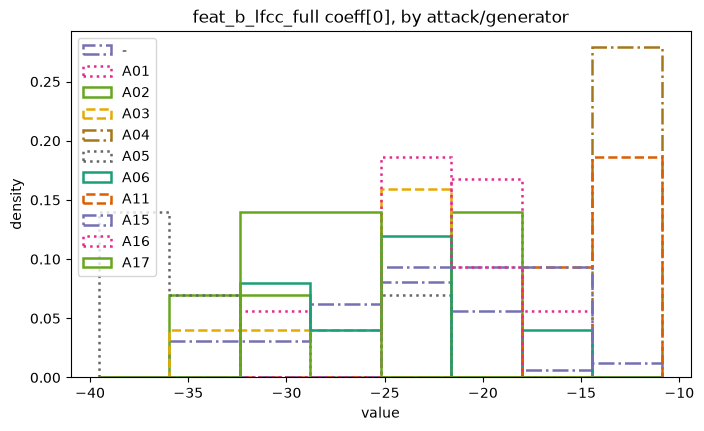

In [8]:
attack_ids = meta_df["attack_id"].to_numpy()
fig, ax = plt.subplots(figsize=(8, 4.5))
values_by_attack = {
    a: demo_mat[attack_ids == a, 0]
    for a in sorted(np.unique(attack_ids))
    if (attack_ids == a).sum() >= 2
}
viz.plot_class_distributions_by_attack(values_by_attack, ax=ax)
ax.set_title(f"{demo_variant} coeff[0], by attack/generator")
plt.show()

### What this shows

c0 (overall level) split by attack instead of pooled as "fake".

### What it means

Read it with care: in this 90-clip sample only 10 of the 19 attacks have at least 2 clips, and
each curve is a handful of clips, so the plot cannot support per-attack claims. A larger check
in the methods note (`Miscellaneous/research/knowledge/methods/lfcc-vs-mfcc-explained.md` §5, 100-150 clips
per attack) found clear per-attack differences in how *quiet* each attack's quietest frames
are: A04, A12, A16 and A09 have unusually deep-quiet or digital-zero frames, which the note
uses to explain much of how A1 behaves per attack when silence is trimmed. Use that analysis,
not this plot, for per-attack conclusions.

## How the level changes over time at the start of a clip

c0 (overall level) of `feat_b_lfcc_full` for the first 1.5 seconds of each clip, with every
clip lined up at its start and **no padding**. Clips shorter than 1.5 s are left out. Lines are
the median of each class; the shaded bands hold the middle 50 % of clips.

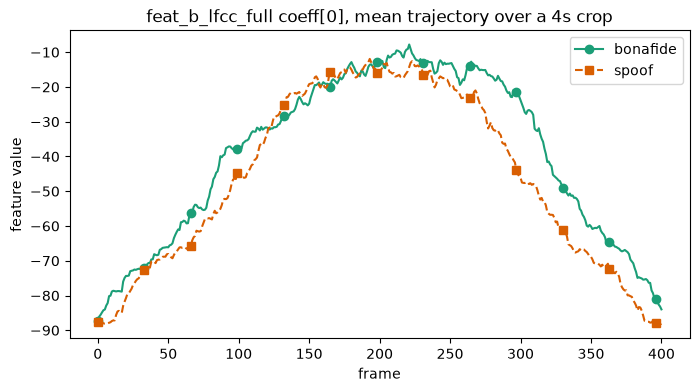

In [9]:
# Line every clip up at its START and look at the first 1.5 s, with no padding at all.
# Zero-padding to a fixed crop would mostly show the added padding and clip length, since
# many clips are shorter than a typical 4 s crop.
hop_s = FEAT_CFG["stft"]["hop_length"] / FEAT_CFG["sr"]
n_frames = int(round(1.5 / hop_s))

traj_by_class: dict[str, list[np.ndarray]] = {"bonafide": [], "spoof": []}
skipped = 0
for row in eda_df.itertuples(index=False):
    x, sr = audio.load_audio(row.path, target_sr=FEAT_CFG["sr"])
    feat = features.extract(x, demo_variant, FEAT_CFG)  # [T, D]
    if feat.shape[0] < n_frames:
        skipped += 1
        continue
    traj_by_class[row.label].append(feat[:n_frames, 0])

t = np.arange(n_frames) * hop_s
fig, ax = plt.subplots(figsize=(9, 4))
for lab, style in [("bonafide", "-"), ("spoof", "--")]:
    m = np.stack(traj_by_class[lab])
    colour = viz.CLASS_COLORS[lab]
    ax.plot(t, np.median(m, axis=0), style, color=colour, lw=2, label=f"{lab} median (n={len(m)})")
    ax.fill_between(t, np.percentile(m, 25, axis=0), np.percentile(m, 75, axis=0), color=colour, alpha=0.18)
ax.set_xlabel("time from the start of the clip (s)")
ax.set_ylabel("c0 (overall level)")
ax.set_title(f"{demo_variant} c0 over the first 1.5 s, clips aligned at their start (bands: middle 50 %)")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
print(f"clips shorter than 1.5 s skipped: {skipped}")

### What to look for

**Note on the stored figure:** the figure saved above does not come from this cell's current
code. It is a 4 s crop in which clips were padded with zeros at both ends (the ramps down to
c0 near -88 at frame 0 and frame 400 are padding, not signal), so it mainly shows padding and
clip length. Re-run the cell to draw the start-aligned plot described here.

When re-run, the plot lines every clip up at its start, so the left edge shows each class's
lead-in before speech:

- if the silence shortcut is present, the **real clips (green)** median stays at a low c0 level
  for longer before rising to speech level;
- the **fake clips (orange)** median rises earlier, because most fakes start speaking almost
  immediately.

### What it means

That pattern would be the **silence shortcut** seen directly in the features a detector uses.
Real recordings in ASVspoof 2019 start with a room lead-in, while many fakes start speaking
at once; Müller et al. 2021 attribute this to generators trained on trimmed speech. A model
that sees c0 over time can learn "quiet start means real" without learning anything about
synthesis. That is what the notebook 01 leakage audit measured (AUC 0.837 from leading silence
alone), and it is consistent with the measured effect of trimming on ASVspoof eval: A1 rises
from 9.56 % to 19.84 % EER and A2 from 0.96 % to 13.27 % (`runs/REGISTRY.md`).

In [10]:
print(f"MODE was: {MODE}")

MODE was: REAL DATA


## Summary: what this notebook does and does not tell you

**What it shows**

1. **No single cepstral coefficient separates real from fake** (per-dimension distributions).
   Detection comes from combining many dimensions, as A1's GMM does.
2. **The DCT turns 20 tangled channels into nearly independent coefficients** (measured mean
   |correlation| 0.851 → 0.166). That makes a diagonal GMM reasonable, and separates level (c0)
   from spectral shape (c1 onwards).
3. **The LFCC differences come in two groups** (panel b of the effect-size figure).
   - Envelope-scale coefficients (c1, c4, c5, c7) are higher in fakes.
   - Fine-detail coefficients (c15-c18) are lower in fakes, down to about -1.1 at c18.

   The fine-detail result fits the long-standing argument for linear filters in spoof
   detection: synthesis "mostly focus[es] on producing identical overall envelope", so finer
   spectral detail is not preserved (Sahidullah et al. 2015, p.2). WaveFake (Frank and
   Schönherr 2021) reports vocoder differences "especially in the higher frequencies" (p.6). A
   larger 600-clip check through A1's exact front end finds the same direction for c16-c18, at
   smaller size (d about -0.4 to -0.6; `Miscellaneous/research/knowledge/methods/lfcc-vs-mfcc-explained.md`,
   finding F-P item 10).
4. **Cutting LFCC to 13 coefficients throws away those fine-detail coefficients,** so it would
   discard the clearest shape difference in this sample.
5. **The silence shortcut shows up in c0** (re-run the start-aligned trajectory cell to see it
   over time; the stored figure there is a zero-padded crop).

**What it does not tell you**

- **Which representation detects best.** That needs the same model trained on each
  representation. The A1 LFCC-versus-MFCC runs (three seeds each, `runs/REGISTRY.md`)
  measured:
  - LFCC better than MFCC on ASVspoof eval (EER 9.56, 8.67, 9.12 % against 10.95, 10.39,
    10.50 %);
  - MFCC much better on real-world In-the-Wild audio (33.15, 30.74, 33.73 % against 58.04,
    45.95, 58.58 %).

  A difference visible in these plots is not automatically a difference a detector uses well
  out of domain.
- **Anything per attack.** There are too few clips per attack here.
- **Exactly A1's features.** This notebook uses a 25 ms Hann window and no pre-emphasis.
  A1 (B02) uses a 20 ms Hamming window with pre-emphasis. Directions agree with the
  B02-pipeline check cited above; sizes differ.
- **Proof.** The sample is 90 clips, so |d| below about 0.4 is within noise.